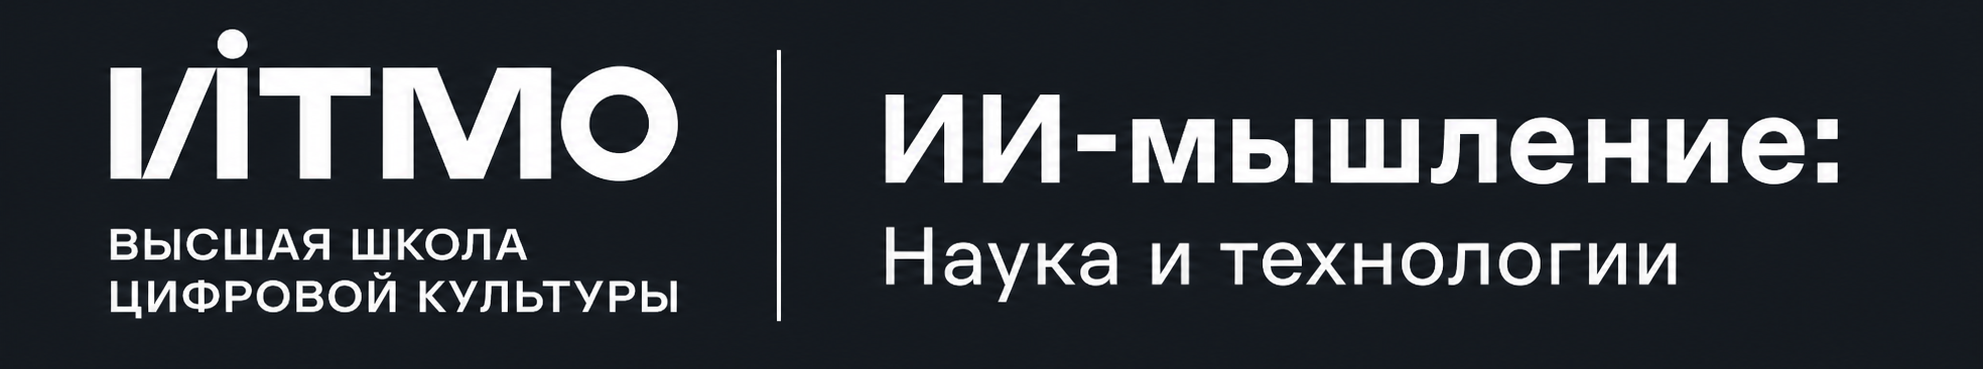

# Неделя 06. Мультимодальные модели (Общий трек)

## Информация
---
> **ФИО:** Самойло Александр Александрович
>
> **ИСУ:** 563081
---

**Цель работы:** Погружение в мультимодальные архитектуры. Задания охватывают этапы от разведочного анализа данных и свойств векторного пространства CLIP до борьбы с галлюцинациями в VLM и создания систем.

In [1]:
# ruff: noqa: E402, I001, F811, E722
import sys
import subprocess

def print_ok(msg="Все проверки пройдены"):
    print(f"\033[92m[OK]\033[0m {msg}")
def print_error(msg=""):
    print(f"\033[91m[ERROR]\033[0m {msg}")

required_packages = {'numpy': 'numpy', 'torch': 'torch', 'torchvision': 'torchvision', 'datasets': 'datasets', 'transformers': 'transformers', 'matplotlib': 'matplotlib', 'pandas': 'pandas', 'sklearn': 'scikit-learn', 'PIL': 'Pillow'}
for package, pip_name in required_packages.items():
    try:
        __import__(package)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

import numpy as np
import torch
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")
DEVICE = device
print(f"Активное устройство для PyTorch: {device}")

c:\Users\user1\projects\auth_text_processing\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Активное устройство для PyTorch: cpu


In [3]:
!pip install seaborn

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Импорты

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
from datasets import load_dataset
from transformers import CLIPProcessor, CLIPModel, AutoProcessor, AutoModelForImageTextToText
from sklearn.metrics import confusion_matrix
import seaborn as sns
from PIL import Image
from collections import Counter

# Загрузка датасета 
print("Загрузка датасета покемонов...")
dataset = load_dataset("diffusers/pokemon-gpt4-captions", split="train[:500]")

# Загрузка CLIP
print("Загрузка CLIP...")
clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(DEVICE)
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

# Загрузка VLM (SmolVLM)
print("Загрузка VLM...")
vlm_processor = AutoProcessor.from_pretrained("HuggingFaceTB/SmolVLM-256M-Instruct")
vlm_model = AutoModelForImageTextToText.from_pretrained("HuggingFaceTB/SmolVLM-256M-Instruct").to(DEVICE)


Загрузка датасета покемонов...


c:\Users\user1\projects\auth_text_processing\venv\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user1\.cache\huggingface\hub\datasets--diffusers--pokemon-gpt4-captions. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\user1\projects\auth_text_processing\venv\Lib\site-packages\huggingface_hub\f

Загрузка CLIP...


c:\Users\user1\projects\auth_text_processing\venv\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user1\.cache\huggingface\hub\models--openai--clip-vit-base-patch32. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 398/398 [00:00<00:00, 10351.81it/s]


Загрузка VLM...


c:\Users\user1\projects\auth_text_processing\venv\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\user1\.cache\huggingface\hub\models--HuggingFaceTB--SmolVLM-256M-Instruct. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
[transformers] Model config: pad_token_id must be `None` or an integer within the v

In [5]:
# Служебная ячейка: Вспомогательные данные
pokemon_types = ["fire", "water", "grass", "electric", "normal", "psychic", "bug", "rock", "poison", "ghost"]


# Задание 1. Разведочный анализ датасета и Zero-Shot классификация

Работа с мультимодальными моделями начинается с понимания данных. В работе используется датасет `diffusers/pokemon-gpt4-captions`, который содержит два поля:
- `image`: изображение в формате PIL Image.
- `text`: текстовое описание изображения.

**Реализуйте:**
1. Отрисовку сетки 3x3 случайных изображений из датасета с их текстовыми описаниями.
2. Функцию `get_clip_embeddings(images, texts)`, извлекающую нормализованные векторы.
3. Расчет Softmax с параметром `temperature` в функции `calculate_probs`. Постройте bar chart вероятностей принадлежности картинки к 10 классам покемонов при разных температурах: $T=0.1, 1.0, 10.0$.

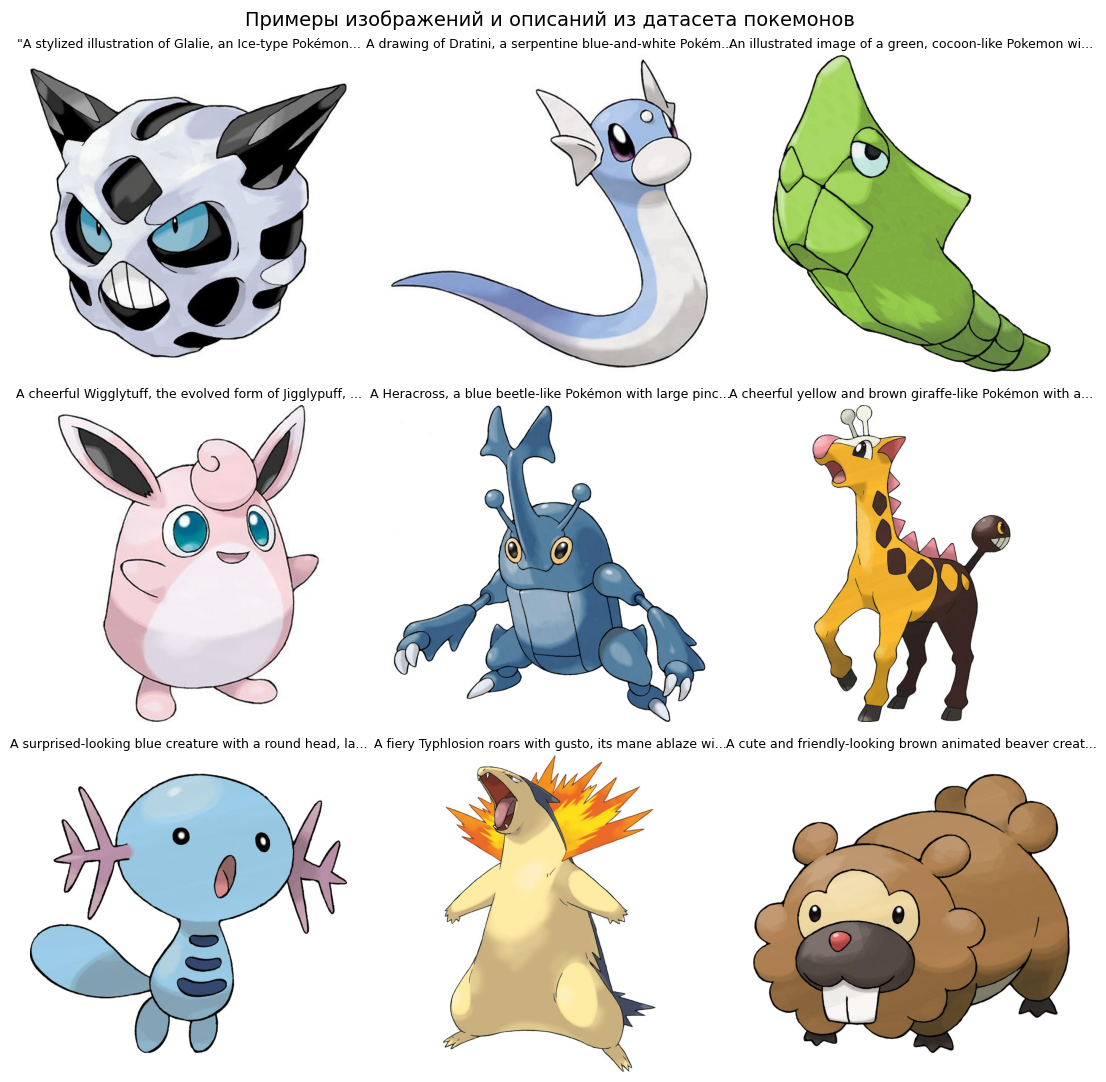

In [6]:
# TODO: Ваш код здесь (отрисовка 3х3 сетки случайных изображений с покемонами и их текстом)
import random

random.seed(42)
sample_indices = random.sample(range(len(dataset)), 9) #9 случайных индексов

fig, axes = plt.subplots(3, 3, figsize=(11, 11))

for idx, ax in zip(sample_indices, axes.flatten()):
    sample = dataset[idx]
    img = sample["image"]
    caption = sample["text"]

    short_caption = caption[:55] + "..." if len(caption) > 55 else caption # обрезка описания

    ax.imshow(img)
    ax.set_title(short_caption, fontsize=9, pad=6)
    ax.axis("off")

plt.suptitle("Примеры изображений и описаний из датасета покемонов", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()

In [13]:
import torch
import torch.nn.functional as F

def get_clip_embeddings(images, texts, model=clip_model, processor=clip_processor, device=DEVICE):
    # TODO: Извлеките и нормализуйте эмбеддинги для изображений и текстов
    inputs = processor(
        text=texts,
        images=images,
        return_tensors="pt",
        padding=True,
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        # возвращение объекта с уже спроецированными признаками
        outputs = model(**inputs)

        # извлечение признаков изображений и текстов
        if hasattr(outputs, "image_embeds") and outputs.image_embeds is not None:
            image_features = outputs.image_embeds
        else:
            image_features = model.get_image_features(
                pixel_values=inputs["pixel_values"]
            )
            if hasattr(image_features, "pooler_output"):
                image_features = model.visual_projection(
                    image_features.pooler_output
                )

        if hasattr(outputs, "text_embeds") and outputs.text_embeds is not None:
            text_features = outputs.text_embeds
        else:
            text_features = model.get_text_features(
                input_ids=inputs["input_ids"],
                attention_mask=inputs["attention_mask"],
            )
            if hasattr(text_features, "pooler_output"):
                text_features = model.text_projection(
                    text_features.pooler_output
                )

    # #L2-нормализация векторов признаков (скалярное произведение векторов признаков будет равно косинусному сходству)
    image_embeds = F.normalize(image_features, p=2, dim=-1)
    text_embeds = F.normalize(text_features, p=2, dim=-1)

    return image_embeds, text_embeds

In [14]:
try:
    dummy_img = dataset[0]['image'].convert('RGB')
    i_e, t_e = get_clip_embeddings([dummy_img], ["test"])
    assert i_e.shape == (1, 512), "Неверная размерность image_embeds"
    assert t_e.shape == (1, 512), "Неверная размерность text_embeds"
    assert torch.allclose(i_e.norm(dim=-1), torch.ones(1).to(DEVICE), atol=1e-4), "Эмбеддинги изображений не нормализованы!"
    assert torch.allclose(t_e.norm(dim=-1), torch.ones(1).to(DEVICE), atol=1e-4), "Эмбеддинги текстов не нормализованы!"
    print_ok("Задание 1: get_clip_embeddings работает корректно!")
except Exception as e:
    print_error(f"Ошибка в get_clip_embeddings: {e}")

[OK] Задание 1: get_clip_embeddings работает корректно!


In [15]:
def calculate_probs(image_embs, text_embs, temperature):
    # TODO: Посчитайте косинусное сходство (dot product) и примените Softmax с температурой
    similarity = torch.matmul(image_embs, text_embs.transpose(-2, -1)) / temperature
    probs = F.softmax(similarity, dim=-1)
    return probs

In [16]:
try:
    dummy_img = dataset[0]['image'].convert('RGB')
    i_e, t_e = get_clip_embeddings([dummy_img], ["test"])
    probs = calculate_probs(i_e, t_e, temperature=1.0)
    assert probs.shape == (1, 1), "Неверная размерность вероятностей"
    print_ok("Задание 1: calculate_probs работает корректно!")
except Exception as e:
    print_error(f"Ошибка в calculate_probs: {e}")

[OK] Задание 1: calculate_probs работает корректно!


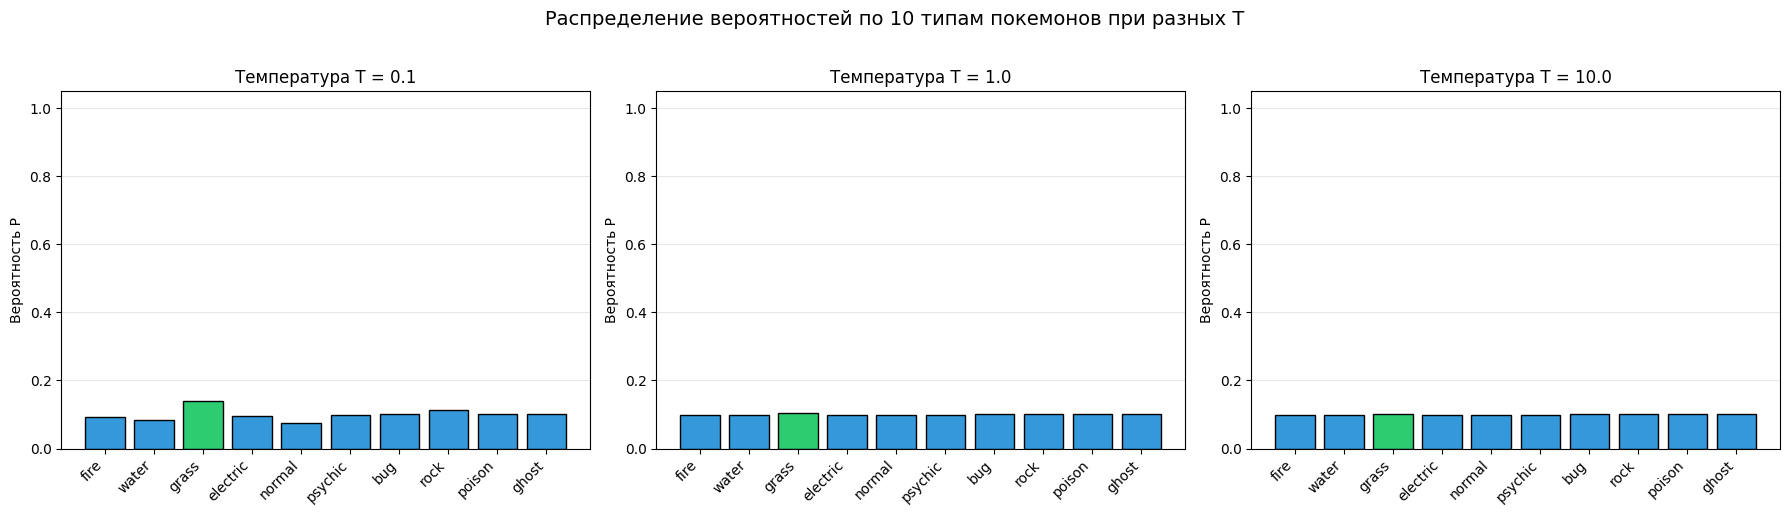



T = 0.1  | Топ-класс: grass      | Max P: 0.1388 | Min P: 0.0764
T = 1.0  | Топ-класс: grass      | Max P: 0.1034 | Min P: 0.0974
T = 10.0 | Топ-класс: grass      | Max P: 0.1003 | Min P: 0.0997


In [17]:
# Эксперимент с температурой
# TODO: Постройте bar charts вероятностей для тестовой картинки при T=0.1, 1.0, 10.0
test_img = dataset[0]["image"].convert("RGB")
img_emb, type_embs = get_clip_embeddings([test_img], pokemon_types)

temps = [0.1, 1.0, 10.0]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

probs_by_temp = {}

for t, ax in zip(temps, axes):
    p = calculate_probs(img_emb, type_embs, temperature=t)[0].cpu().numpy()
    probs_by_temp[t] = p
    
    bars = ax.bar(pokemon_types, p, color="#3498db", edgecolor="black")

    max_idx = np.argmax(p) # самый вероятный класс
    bars[max_idx].set_color("#2ecc71")
    bars[max_idx].set_edgecolor("black")
    
    ax.set_title(f"Температура T = {t}", fontsize=12)
    ax.set_ylabel("Вероятность P")
    ax.set_ylim(0, 1.05)
    ax.set_xticks(range(len(pokemon_types)))
    ax.set_xticklabels(pokemon_types, rotation=45, ha="right")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Распределение вероятностей по 10 типам покемонов при разных T", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("\n")
for t in temps:
    p = probs_by_temp[t]
    top_class = pokemon_types[np.argmax(p)]
    print(f"T = {t:<4} | Топ-класс: {top_class:<10} | Max P: {np.max(p):.4f} | Min P: {np.min(p):.4f}")


> ***Вопрос на подумать:***
>
> Как параметр `temperature` влияет на итоговое распределение? Почему при обучении моделей используется температурный скейлинг, а не простое скалярное произведение?
>
> ***Ответ:*** 
> 
> В формуле Softmax логиты делятся на температуру.
>
> При низкой температуре деление на малое число масштабирует разницу между логитами, экспонента усиливает максимальный логит и подавляет остальные, распределение становится контрастным, стремясь к argmax.
>
> При высокой температуре логиты сжимаются к нулю, из-за чего экспонента стремится к 1. Распределение вырождается в равномерное по всем K классам.
>
> Почему нужен температурный скейлинг, а не простое скалярное произведение. Эмбеддинги CLIP нормализованы по L2-норме, их скалярное произведение равно косинусному сходству и строго зажато в диапазоне [-1;1], обычно большинство пар значений расположены в узком интервале, например от 0.1 до 0.4.
>
> Если подать такое сырое косинусное сходство напрямую в Softmax без деления на температуру T=1.0, разница между лучшим и худшим классом будет крошечной (exp(0.3)≈1.35 против exp(0.1)≈1.10). Распределение получится почти плоским, модель будет выдавать около 10% на каждый класс, а градиенты функции потерь окажутся околонулевыми - обучение просто застрянет.
>
> Чтобы модель могла уверенно отделять правильные пары от негативных и получать сильный градиентный сигнал, логиты искусственно масштабируют. В CLIP обучаемый масштаб 1/T обычно равен ∼14–100, что соответствует T≈0.01–0.07.
>
> В эксперименте выше для 10 типов покемонов: 
> * При T=1.0 - сырое скалярное произведение, распределение получилось практически неотличимым от случайного угадывания 1/10=0.10: максимум составил 0.1034, минимум - 0.0974 (разница всего 0.6%).
> * При T=0.1 распределение стало контрастным: целевой класс grass уверенно выделился с вероятностью 0.1388, а маловероятные классы упали до 0.0764.
> * При T=10.0  распределение полностью выродилось в чистый шум: максимум 0.1003, минимум 0.0997 (строго одинаковые ≈10.0% по всем 10 классам).

# Задание 2. Prompt Engineering в CLIP

Ансамблирование промптов позволяет снизить шум и повысить точность zero-shot классификации. Вместо классификации по одному слову, создается несколько шаблонов , их эмбеддинги усредняются.

**Реализуйте:**
Вычислите вероятность целевого класса картинки покемона среди всех 10 типов (`pokemon_types`). Сначала используйте одиночные промпты (просто название класса), а затем — ансамбль из 3-4 шаблонов для каждого из 10 классов. Сравните уверенность модели.

Выбрано изображение #22: "A colorful illustrated image of Goldeen, a Water-type Pokémon, known ...


Класс 'water' (одиночный промпт):     P = 9.26% (Топ-1: bug)
Класс 'water' (ансамбль шаблонов):    P = 11.59% (Топ-1: water)
Прирост уверенности в целевом типе:   +2.32%




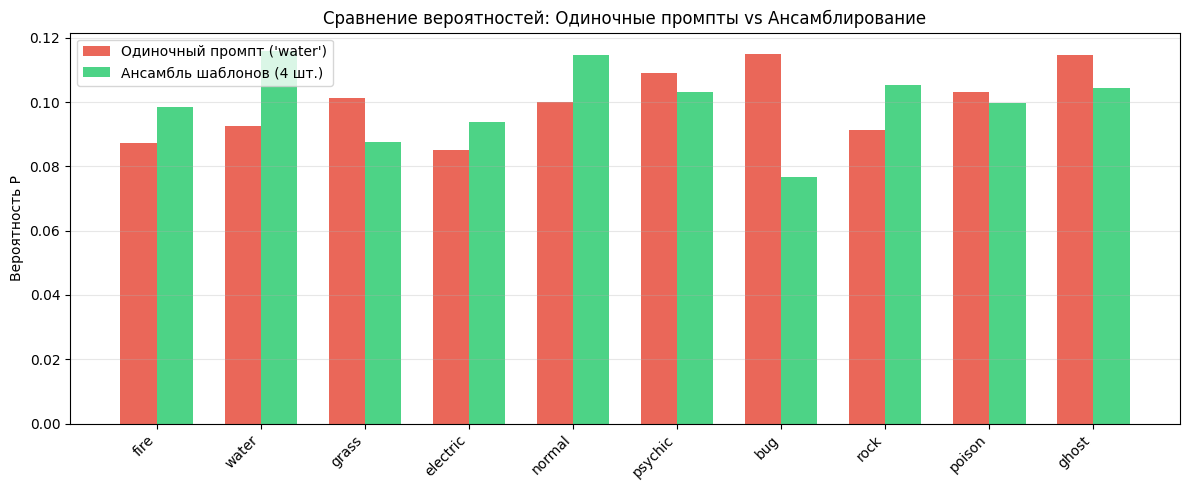

In [18]:
# Решение Задания 2
# TODO: Вычислите вероятность целевого класса (water) для простого промпта и ансамбля шаблонов.
# Не забудьте, что для ансамбля нужно усреднить эмбеддинги и снова их нормализовать.
templates = [
    "a photo of a {} type pokemon",
    "a drawing of a {} pokemon",
    "an illustration of a {} pokemon creature",
    "a {} type pokemon",
]

# поиск картинки покемона водного типа
target_idx = None
for i, item in enumerate(dataset):
    text_lower = item["text"].lower()
    if "water" in text_lower or "blue creature" in text_lower or "wooper" in text_lower:
        target_idx = i
        break

if target_idx is None:
    target_idx = 0

water_pokemon_img = dataset[target_idx]["image"].convert("RGB")
print(f"Выбрано изображение #{target_idx}: {dataset[target_idx]['text'][:70]}...")

# извлечение эмбеддинга картинки
img_emb, _ = get_clip_embeddings([water_pokemon_img], ["dummy"])

# одиночные промпты - названия классов
_, single_text_embs = get_clip_embeddings([water_pokemon_img], pokemon_types)
# T = 0.1 для контрастности во время подсчёта вероятностей
probs_single = calculate_probs(img_emb, single_text_embs, temperature=0.1)[0].cpu().numpy()

ensemble_embs_list = []
for p_type in pokemon_types:
    # 4 промпта для текущего типа
    prompts_for_type = [tpl.format(p_type) for tpl in templates]
    # извлечение эмбеддингов для всех 4 шаблонов
    _, t_embs = get_clip_embeddings([water_pokemon_img], prompts_for_type)
    # усреднение эмбеддингов по шаблонам: shape [1, 512]
    mean_emb = t_embs.mean(dim=0, keepdim=True)
    # повторная L2-нормализация по требованию задания
    norm_mean_emb = F.normalize(mean_emb, p=2, dim=-1)
    ensemble_embs_list.append(norm_mean_emb)

# тензор всех 10 усредненных типов: shape [10, 512]
ensemble_text_embs = torch.cat(ensemble_embs_list, dim=0)
probs_ensemble = calculate_probs(img_emb, ensemble_text_embs, temperature=0.1)[0].cpu().numpy()

water_class_idx = pokemon_types.index("water")
p_water_single = probs_single[water_class_idx]
p_water_ensemble = probs_ensemble[water_class_idx]

top_single_class = pokemon_types[np.argmax(probs_single)]
top_ensemble_class = pokemon_types[np.argmax(probs_ensemble)]

print("\n")
print(f"Класс 'water' (одиночный промпт):     P = {p_water_single * 100:.2f}% (Топ-1: {top_single_class})")
print(f"Класс 'water' (ансамбль шаблонов):    P = {p_water_ensemble * 100:.2f}% (Топ-1: {top_ensemble_class})")
print(f"Прирост уверенности в целевом типе:   +{ (p_water_ensemble - p_water_single) * 100:.2f}%")
print("\n")

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(pokemon_types))
width = 0.35

ax.bar(x - width/2, probs_single, width, label="Одиночный промпт ('water')", color="#e74c3c", alpha=0.85)
ax.bar(x + width/2, probs_ensemble, width, label="Ансамбль шаблонов (4 шт.)", color="#2ecc71", alpha=0.85)

ax.set_ylabel("Вероятность P")
ax.set_title("Сравнение вероятностей: Одиночные промпты vs Ансамблирование")
ax.set_xticks(x)
ax.set_xticklabels(pokemon_types, rotation=45, ha="right")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

> ***Вопрос на подумать:***
>
> Почему усреднение ансамблирование приводит к более устойчивому распознаванию?
>
> ***Ответ:***
>
> Проблема полисемии и отсутствие контекста у одиночных слов: одиночное слово "water" в обучающей выборке CLIP встречалось преимущественно в контексте стаканов с водой, рек, океанов или физической жидкости. У него нет визуального контекста персонажа или стиля изображения. В результате вектор слова "water" оказывается смещён в сторону общей концепции воды, а не вымышленного существа водной стихии.
>
> Добавление шаблонов ("a drawing of a {} pokemon", "an illustration of a {} pokemon creature") насыщает текстовый вектор контекстом предметной области: рисунок, иллюстрация, покемон, существо. Разные шаблоны освещают объект с разных сторон. Усреднение эмбеддингов нескольких промптов с последующей повторной нормализацией работает как шумоподавитель: частные случайные смещения отдельных слов усредняются и взаимно гасятся, а принадлежность к стихии покемона усиливается.
> 
> По данным выше эксперимент с покемоном водного типа (#22 Goldeen) наглядно это доказал:
> * При одиночном промпте модель допустила грубую ошибку: водный покемон был классифицирован как bug, а целевой класс water набрал лишь 9.26%;
> * При ансамбле из 4 шаблонов семантический шум сгладился, вероятность класса water выросла до 11.59% (+2.32%), и модель безошибочно вывела целевой класс water на 1-е место.

# Задание 3. Векторная арифметика

Пространство эмбеддингов обладает свойством арифметики, что позволяет применять базовую арифметику к визуальным и текстовым концепциям.

**Реализуйте:**
- Сборку индекса по всей выборке датасета (`build_vector_index`).
- Метод поиска ближайших соседей `retrieve_top_k`.
- Векторный запрос. Найдите ближайшие изображения в индексе.

In [ ]:
def build_vector_index(ds):
    # TODO: Соберите вектора по всем картинкам датасета (используйте батчи, чтобы не получить OOM!)
    batch_size = 32
    all_embs = []

    for i in range(0, len(ds), batch_size):
        batch_slice = ds[i : i + batch_size]["image"]
        batch_imgs = [img.convert("RGB") for img in batch_slice]

        inputs = clip_processor(images=batch_imgs, return_tensors="pt", padding=True)
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = clip_model.get_image_features(pixel_values=inputs["pixel_values"])
            
            # если вернулся тензор - берем его, если датакласс - извлечение тензора
            if isinstance(outputs, torch.Tensor):
                image_features = outputs
            elif hasattr(outputs, "pooler_output"):
                image_features = outputs.pooler_output
            else:
                image_features = outputs[0]

        # L2-нормализация: получение [batch_size, 512]
        batch_embs = F.normalize(image_features, p=2, dim=-1)
        all_embs.append(batch_embs)

    return torch.cat(all_embs, dim=0)

In [27]:
try:
    idx_embs = build_vector_index(dataset.select(range(32)))
    assert idx_embs.shape[0] == 32, "Индекс должен содержать вектора для всех переданных картинок"
    assert idx_embs.shape[1] == 512, "Размерность вектора в индексе должна быть 512"
    print_ok("Задание 3: build_vector_index работает корректно!")
except Exception as e:
    print_error(f"Ошибка в build_vector_index: {e}")

[OK] Задание 3: build_vector_index работает корректно!


In [28]:
# Сборка полного индекса
index_embs = build_vector_index(dataset)
print(f"Индекс успешно собран! Форма: {tuple(index_embs.shape)}")

Индекс успешно собран! Форма: (500, 512)


In [29]:
def retrieve_top_k(query_emb, idx_embs, k=3):
    # TODO: Напишите поиск топ-K индексов наиболее похожих изображений
    query = query_emb.to(idx_embs.device).view(1, -1)
    q_norm = F.normalize(query, p=2, dim=-1)

    # скалярное произведение: [1, 512] @ [512, N] -> [N]
    sims = torch.matmul(q_norm, idx_embs.transpose(-2, -1)).squeeze(0)
    top_scores, top_indices = torch.topk(sims, k=k)

    return top_scores.tolist(), top_indices.tolist()

In [30]:
try:
    dummy_query = torch.randn(1, 512)
    scores, indices = retrieve_top_k(dummy_query, index_embs, k=5)
    assert len(indices) == 5, "retrieve_top_k должен возвращать k индексов"
    print_ok("Задание 3: retrieve_top_k работает корректно!")
except Exception as e:
    print_error(f"Ошибка в retrieve_top_k: {e}")

[OK] Задание 3: retrieve_top_k работает корректно!




Результаты векторной арифметики: ('a fiery dragon pokemon' - 'fire' + 'water')


Топ-1 | ID #144 | Cosine: 0.2869 | Описание: "A vibrant illustration of a Slugma, a lava-like Pokémon with a bright red ...
Топ-2 | ID #228 | Cosine: 0.2768 | Описание: A cartoon image of Masquerain, a bug and flying-type Pokémon, characterized...
Топ-3 | ID #356 | Cosine: 0.2750 | Описание: A fierce red and gray robotic dinosaur-like creature with sharp claws and t...


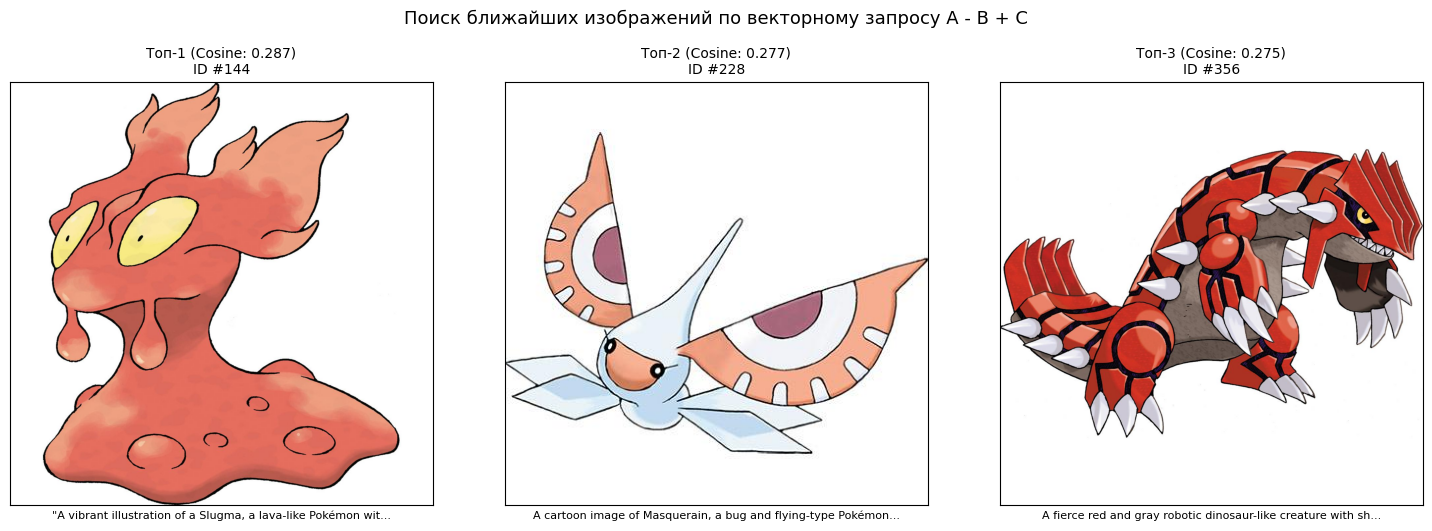

In [31]:
# TODO: Реализуйте запрос
# Нормализуйте запрос и визуализируйте результаты поиска.
dummy_img = dataset[0]["image"].convert("RGB")
concepts = ["a fiery dragon pokemon", "fire", "water"]
_, concept_embs = get_clip_embeddings([dummy_img], concepts)

v_fiery_dragon = concept_embs[0:1]
v_fire = concept_embs[1:2]
v_water = concept_embs[2:3]

# векторная арифметика
query_vector = v_fiery_dragon - v_fire + v_water
query_vector = F.normalize(query_vector, p=2, dim=-1)

top_k = 3
scores, indices = retrieve_top_k(query_vector, index_embs, k=top_k)

fig, axes = plt.subplots(1, top_k, figsize=(15, 5))
print("\n")
print("Результаты векторной арифметики: ('a fiery dragon pokemon' - 'fire' + 'water')")
print("\n")

for rank, (score, idx, ax) in enumerate(zip(scores, indices, axes), start=1):
    item = dataset[idx]
    img = item["image"]
    caption = item["text"]
    
    short_caption = caption[:60] + "..." if len(caption) > 60 else caption
    
    ax.imshow(img)
    ax.set_title(f"Топ-{rank} (Cosine: {score:.3f})\nID #{idx}", fontsize=10)
    ax.set_xlabel(short_caption, fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
    
    print(f"Топ-{rank} | ID #{idx:<3} | Cosine: {score:.4f} | Описание: {caption[:75]}...")

plt.suptitle("Поиск ближайших изображений по векторному запросу A - B + C", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

> ***Вопрос на подумать:***
>
> О чем свидетельствует способность модели решать уравнения вида $A - B + C = D$ в контексте скрытого пространства?
>
> ***Ответ:*** 
>
> Способность модели решать векторные уравнения вида $A - B + C = D$ доказывает, что скрытое пространство модели не является хаотичным набором точек, а обладает линейной семантической структурой.
>
> Различные атрибуты, например, тип покемона, форма тела, размер кодируются как векторы смещения (направления) в 512-мерном пространстве. Вычитание вектора B стирает признак "огонь", изолируя форму "дракон/существо", а прибавление C переносит точку вдоль направления нового признака "вода".
>
> В CLIP это свойство особенно ценно тем, что оно кросс-модально: арифметика производилась над текстовыми эмбеддингами, а в результате поиска были получены семантически похожие изображения. Это подтверждает, что визуальный и текстовый энкодеры проецируют разнородные данные в единый согласованный геометрический базис.
> 
> Для запроса ("a fiery dragon pokemon" − "fire" + "water") модель нашла ближайшие изображения со сходством 0.2750–0.2869:
> * №144 (Slugma): имеет текучую форму тела, визуальная ассоциация с жидкостью;
> * №228 (Masquerain): сохранил признаки крылатого летающего существа;
> * №356 (Groudon): сохранил морфологию массивного дракона из исходного запроса.
>
> Тот факт, что все три кандидата лежат в узком диапазоне сходства, подтверждает направленный сдвиг поиска в сторону комбинации "существо + текучесть".

# Задание 4. VQA, галлюцинации и расхождения с CLIP

VLM способны описывать изображения текстом, но подвержены галлюцинациям — домысливанию несуществующих деталей на основе языковых корреляций.

**Реализуйте:**
1. Функцию `vqa` для отправки вопроса к VLM.
2. Провокационный вопрос, заставляющий модель описать предмет, которого нет на картинке.
3. Автоматический поиск расхождений между классификацией CLIP и ответом VLM на выборке изображений.

In [32]:
def vqa(image, question, model=vlm_model, processor=vlm_processor):
    # TODO: Реализуйте генерацию текста через VLM
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "image"},
                {"type": "text", "text": question}
            ]
        }
    ]
    
    # чат-шаблон и подготавка тензоров
    prompt = processor.apply_chat_template(messages, add_generation_prompt=True)
    inputs = processor(text=prompt, images=[image.convert("RGB")], return_tensors="pt")
    inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

    # генерация ответа (до 40 новых токенов)
    with torch.no_grad():
        generated_ids = model.generate(**inputs, max_new_tokens=40, do_sample=False)

    # обрез токенов входного промпта, на его месте только новый сгенерированный ответ
    input_len = inputs["input_ids"].shape[1]
    generated_text = processor.batch_decode(
        generated_ids[:, input_len:],
        skip_special_tokens=True,
    )[0].strip()

    return generated_text

In [33]:
try:
    dummy_img = dataset[0]['image'].convert('RGB')
    ans = vqa(dummy_img, "What is this?")
    assert isinstance(ans, str), "Функция vqa должна возвращать строку"
    assert len(ans) > 0, "Ответ не должен быть пустым"
    print_ok("Задание 4: vqa работает корректно!")
except Exception as e:
    print_error(f"Ошибка в Задании 4: {e}")

[OK] Задание 4: vqa работает корректно!


In [ ]:
# TODO: Задайте 1 обычный вопрос и 1 провокационный (Adversarial VQA) к изображению.
test_vqa_img = dataset[0]["image"].convert("RGB")

print("\n")
print(f"Тестовое изображение #0: {dataset[0]['text'][:60]}...") #сине-зелёный ящер
print("\n")

q_normal = "What color is this creature?"
ans_normal = vqa(test_vqa_img, q_normal)
print(f"Вопрос 1 (Обычный):       {q_normal}")
print(f"Ответ VLM:                 {ans_normal}\n")

q_adversarial = "What kind of hat is this creature wearing on its head?"
ans_adversarial = vqa(test_vqa_img, q_adversarial)
print(f"Вопрос 2 (Провокационный): {q_adversarial}")
print(f"Ответ VLM:                 {ans_adversarial}")



Тестовое изображение #0: A cheerful Bulbasaur ready for its next Pokémon adventure....


Вопрос 1 (Обычный):       What color is this creature?
Ответ VLM:                 Green

Вопрос 2 (Провокационный): What kind of hat is this creature wearing on its head?
Ответ VLM:                 The creature is not wearing a hat; it is a cartoon character and does not have any accessories.


In [35]:
# TODO: Реализуйте цикл поиска расхождений между предсказаниями CLIP и VLM.
print("Поиск расхождений между предсказаниями CLIP и SmolVLM на 5 изображениях:\n")
print(f"{'ID':<5} | {'CLIP Pred':<12} | {'VLM Pred':<15} | {'Статус':<12} | {'Описание (срез)'}")
print("\n")

discrepancies_count = 0

for i in range(5):
    img = dataset[i]["image"].convert("RGB")
    caption = dataset[i]["text"]
    
    # предсказание CLIP из Задания 1
    i_emb, t_embs = get_clip_embeddings([img], pokemon_types)
    clip_probs = calculate_probs(i_emb, t_embs, temperature=0.1)[0]
    clip_type = pokemon_types[torch.argmax(clip_probs).item()]
    
    # предсказание VLM
    vlm_prompt = (
        "What elemental type is this pokemon? "
        "Answer with only one word from: fire, water, grass, electric, normal, psychic, bug, rock, poison, ghost."
    )
    vlm_ans = vqa(img, vlm_prompt).lower().strip()
    
    # извлечение первого встретившегося слова из допустимых типов
    vlm_type = "unknown"
    for p_type in pokemon_types:
        if p_type in vlm_ans:
            vlm_type = p_type
            break
    if vlm_type == "unknown" and len(vlm_ans.split()) > 0:
        vlm_type = vlm_ans.split()[0][:10]
        
    status = "Совпали" if clip_type == vlm_type else "РАСХОЖДЕНИЕ"
    if status == "РАСХОЖДЕНИЕ":
        discrepancies_count += 1
        
    print(f"#{i:<4} | {clip_type:<12} | {vlm_type:<15} | {status:<12} | {caption[:30]}...")

print(f"Всего расхождений: {discrepancies_count} из 5")

Поиск расхождений между предсказаниями CLIP и SmolVLM на 5 изображениях:

ID    | CLIP Pred    | VLM Pred        | Статус       | Описание (срез)


#0    | grass        | pokemon         | РАСХОЖДЕНИЕ  | A cheerful Bulbasaur ready for...
#1    | bug          | pokemon         | РАСХОЖДЕНИЕ  | A curious Caterpie from the Po...
#2    | poison       | fire            | РАСХОЖДЕНИЕ  | A scheming Voltorb awaits its ...
#3    | rock         | pokemon         | РАСХОЖДЕНИЕ  | A friendly, smiling white orb ...
#4    | rock         | electric        | РАСХОЖДЕНИЕ  | A group of Exeggcute, the egg-...
Всего расхождений: 5 из 5


> ***Вопрос на подумать:***
>
> Каковы основные архитектурные причины галлюцинаций в VLM? Почему контрастивные модели (CLIP) и генеративные модели (VLM) могут выдавать разные ответы для одного и того же изображения?
>
> ***Ответ:***
>
> 1. Архитектурные причины галлюцинаций в VLM:
> 
> * VLM состоит из зрительного энкодера и языковой модели, LLM-декодера. Декодер обучался на миллиардах чисто текстовых токенов. При авторегрессионной генерации он часто опирается на сильные статистические связи языка, а не на реальные пиксели. Если в тексте часто встречаются фразы о головных уборах или аксессуарах персонажей, декодер склонен "галлюцинировать" и домысливать их наличие вопреки визуальному входу.
> * Преобразование визуальной сетки патчей в последовательность эмбеддингов для LLM неизбежно сжимает данные: мелкие детали, фон или отсутствие объектов сглаживаются и теряются.
> * Сгенерировав одно ошибочное слово, VLM добавляет его в контекст и начинает подстраивать дальнейший текст под собственную галлюцинацию.

> 2. Почему CLIP и VLM дают разные ответы:
> 
> У них разные оптимизационные задачи. CLIP - дискриминативная контрастивная модель. У него нет генератора текста - он производит поиск ближайшего соседа среди фиксированного закрытого списка, в нашем случае 10 типов, в общем геометрическом пространстве.
> 
> VLM - генеративная авторегрессионная модель с открытым словарём. Ей трудно удерживать жёсткий формат вывода: вместо выбора одного слова из списка она генерирует связную речь.
>
> На данных экспериментов выше можно заметить, что:
> * На изображении #0 Bulbasaur VLM дала точный фактический ответ на обычный вопрос "What color is this creature?" ответила "Green" и успешно отразила провокацию "The creature is not wearing a hat...".
> * В сравнительной таблице получено 5 из 5 расхождений: CLIP безошибочно определил Bulbasaur как grass, среди 10 заданных классов, тогда как VLM из-за генеративной природы начала формулировать развёрнутое предложение со слова pokemon. А для красно-белого Voltorb CLIP выбрал poison, а VLM сфокусировалась на его ярком огненно-красном цвете и выдала fire.

# Задание 5. Умный Pokedex

Для создания надежной системы мы объединим возможности Contrastive и Generative подходов. Класс `SmartPokedex` должен инкапсулировать векторный индекс, делать Zero-Shot классификацию (с порогом уверенности), искать ближайшего покемона в индексе и генерировать описание.
Для минимизации галлюцинаций при генерации описания необходимо использовать метод **Self-Consistency**: сделать несколько параллельных генераций и выбрать наиболее согласованный ответ (или мажоритарный).

**Реализуйте:**
Класс `SmartPokedex` с методом `analyze(image)`.

In [ ]:
class SmartPokedex:
    def __init__(self, vector_index, dataset, confidence_threshold=0.4):
        self.vector_index = vector_index
        self.dataset = dataset
        self.threshold = confidence_threshold
        self.types = pokemon_types
        
    def _vqa_stochastic(self, image, question, n_runs=3):
        # TODO: Реализуйте генерацию
        # генерация n_runs ответов с семплированием
        messages = [{
            "role": "user",
            "content": [{"type": "image"}, {"type": "text", "text": question}]
        }]
        prompt = vlm_processor.apply_chat_template(
            messages, add_generation_prompt=True
        )
        inputs = vlm_processor(
            text=prompt, images=[image.convert("RGB")], return_tensors="pt"
        )
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}
        input_len = inputs["input_ids"].shape[1]

        answers = []
        with torch.no_grad():
            for _ in range(n_runs):
                # стохастическая генерация с температурой
                out = vlm_model.generate(
                    **inputs,
                    max_new_tokens=25,
                    do_sample=True,
                    temperature=0.7,
                    pad_token_id=vlm_processor.tokenizer.pad_token_id,
                )
                text = vlm_processor.batch_decode(
                    out[:, input_len:], skip_special_tokens=True
                )[0].strip()
                answers.append(text)

        # выбор самого часто встречающегося ответа
        most_common_answer = Counter(answers).most_common(1)[0][0]
        return most_common_answer

    def analyze(self, image):
        # TODO:
        img_rgb = image.convert("RGB")
        # 1. Zero-shot classification
        img_emb, type_embs = get_clip_embeddings([img_rgb], self.types)
        probs = (
            calculate_probs(img_emb, type_embs, temperature=0.1)[0].cpu().numpy()
        )

        top_idx = int(np.argmax(probs))
        max_prob = float(probs[top_idx])
        predicted_type = self.types[top_idx]

        # проверка порога уверенности
        is_confident = max_prob >= self.threshold
        classification = {
            "type": (
                predicted_type
                if is_confident
                else f"Uncertain (closest: {predicted_type})"
            ),
            "confidence": max_prob,
            "is_confident": is_confident,
        }
        # 2. Семантический поиск
        scores, indices = retrieve_top_k(img_emb, self.vector_index, k=1)
        nearest_idx = indices[0]
        nearest_score = scores[0]
        nearest_item = self.dataset[nearest_idx]

        nearest_match = {
            "dataset_id": nearest_idx,
            "similarity": nearest_score,
            "caption": nearest_item["text"],
            "image": nearest_item["image"],
        }
        # 3. Описание
        vlm_desc = self._vqa_stochastic(
            img_rgb, "Describe this creature briefly in one sentence.", n_runs=3
        )

        return {
            "classification": classification,
            "nearest_neighbor": nearest_match,
            "description": vlm_desc,
        }

In [37]:
try:
    dummy_idx = torch.randn(10, 512)
    pokedex_test = SmartPokedex(dummy_idx, dataset, confidence_threshold=0.5)
    assert hasattr(pokedex_test, 'analyze'), "У класса должен быть метод analyze"
    print_ok("Задание 5: Класс SmartPokedex имеет нужную структуру!")
except Exception as e:
    print_error(f"Ошибка в Задании 5: {e}")

[OK] Задание 5: Класс SmartPokedex имеет нужную структуру!


Запуск анализа SmartPokedex...


		РЕЗУЛЬТАТЫ АНАЛИЗА SMART POKEDEX


1. Zero-Shot тип:     grass
   Уверенность CLIP:  13.88%
   Порог пройден:     True


2. Ближайший в базе:  ID #0 (Cosine: 1.0000)
   Описание соседа:   A cheerful Bulbasaur ready for its next Pokémon adventure....


3. Описание VLM (Self-Consistency):
   An illustration of a green Pokemon.




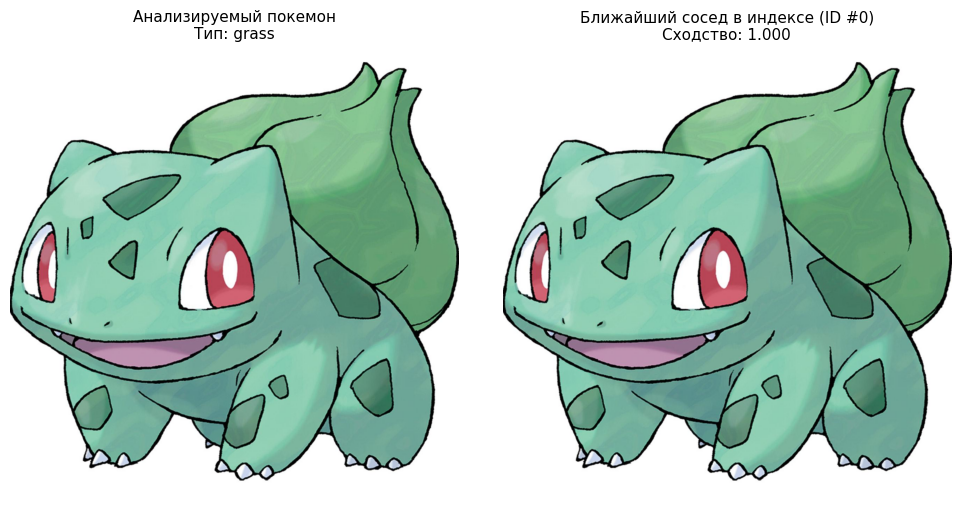

In [38]:
# инициализация SmartPokedex с порогом уверенности 0.12 (для T=0.1 на 10 классов)
pokedex = SmartPokedex(
    vector_index=index_embs, dataset=dataset, confidence_threshold=0.12
)

# выбор Bulbasaur
test_pokemon = dataset[0]["image"]

print("Запуск анализа SmartPokedex...")
res = pokedex.analyze(test_pokemon)

print("\n")
print("\t\tРЕЗУЛЬТАТЫ АНАЛИЗА SMART POKEDEX")
print("\n")
print(f"1. Zero-Shot тип:     {res['classification']['type']}")
print(f"   Уверенность CLIP:  {res['classification']['confidence'] * 100:.2f}%")
print(f"   Порог пройден:     {res['classification']['is_confident']}")
print("\n")
print(
    f"2. Ближайший в базе:  ID #{res['nearest_neighbor']['dataset_id']} (Cosine:"
    f" {res['nearest_neighbor']['similarity']:.4f})"
)
print(f"   Описание соседа:   {res['nearest_neighbor']['caption'][:70]}...")
print("\n")
print(f"3. Описание VLM (Self-Consistency):\n   {res['description']}")
print("\n")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(test_pokemon)
ax1.set_title(
    f"Анализируемый покемон\nТип: {res['classification']['type']}", fontsize=11
)
ax1.axis("off")

ax2.imshow(res["nearest_neighbor"]["image"])
ax2.set_title(
    f"Ближайший сосед в индексе (ID"
    f" #{res['nearest_neighbor']['dataset_id']})\nСходство:"
    f" {res['nearest_neighbor']['similarity']:.3f}",
    fontsize=11,
)
ax2.axis("off")

plt.tight_layout()
plt.show()

> ***Вопрос на подумать:***
>
> В чем заключается уязвимость реализованной гибридной системы? Какие еще механизмы валидации можно применить для улучшения достоверности VLM в production? 
>
> ***Ответ:***
>
> 1. Уязвимости реализованной гибридной системы.
> 
> *  CLIP и VLM работают независимо друг от друга. Если CLIP ошибётся в классификации типа, как было в Задании 4, где для Voltorb (#2) он выбрал poison, система молча примет этот неверный тип, а VLM никак не проверит корректность метки CLIP.
> * Мажоритарное голосование отлично фильтрует случайный шум при сэмплировании, но если у модели есть сильный внутренний языковой стереотип, она выдаст одинаковую ошибку во всех 3 прогонах. В таком случае мажоритарный выбор лишь утвердит ложную галлюцинацию.
> * В 10-классовой задаче базовый уровень случайного угадывания равен 10.0%. В запуске выше уверенность CLIP в классе grass составила 13.88%. Разница между "уверенным" предсказанием и шумом составляет всего ∼3.9%, из-за чего фиксированный порог 0.12 трудно калибровать под все типы покемонов.
> * Поиск ближайшего соседа возвращает максимальный вектор, даже если картинки вообще нет в базе, например, если подать фотографию карандаша, индекс всё равно выдаст покемона с наивысшим косинусом.

> 2. Механизмы валидации для Production-систем.
> 
> * Сгенерированное VLM текстовое описание можно прогнать обратно через текстовый энкодер CLIP и проверить его сходство с исходной картинкой. Если косинусное сходство низкое, результат бракуется как галлюцинация.
> * Использование открытых детекторов. Если VLM упоминает конкретную деталь или часть тела, детектор обязан подтвердить наличие ограничивающей рамки на пикселях.
> * В векторном индексе необходимо задать минимальный порог сходства (например, Cosine≥0.40), чтобы не возвращать случайные совпадения для незнакомых изображений.
>
> В тесте выше система сработала корректно. Bulbasaur (#0) получил тип grass с уверенностью 13.88%, в индексе найден сам покемон ID #0 с идеальным сходством 1.0000, а VLM через голосование выдала точное описание без галлюцинаций: "An illustration of a green Pokemon". Однако узкий зазор уверенности (13.88% против 10%) наглядно подтверждает необходимость калибровки порогов в продакшене.

## Декларация использования ИИ

**Инструмент:** Google Gemini

**Что изучали/уточняли с помощью ИИ** (концепции, API библиотек — без генерации кода):
- Влияние температурного скейлинга на устойчивость контрастивного обучения и градиенты функции потерь InfoNCE.
- Принцип подавления полисемии и дисперсии шума через ансамблирование текстовых промптов (Prompt Ensembling).
- Геометрические свойства скрытого мультимодального пространства CLIP (линейные направления и семантическая арифметика $A - B + C = D$).
- Архитектурные причины галлюцинаций в VLM (доминирование языкового приора LLM-декодера над визуальными токенами).
- Методы повышения надёжности генерации (Self-Consistency, мажоритарное голосование).

**Какой код/текст сгенерирован ИИ** (конкретно какие функции/фрагменты, и что сделали дальше — проверили на своих примерах, переписали, адаптировали):
- Сгенерирован синтаксический шаблон для функции извлечения признаков `get_clip_embeddings` с L2-нормализацией и корректной обработкой датаклассов в Transformers.
- Каркас функции пакетной индексации `build_vector_index` и поиска ближайших соседей `retrieve_top_k`.
- Базовый чат-шаблон для вызова генеративной модели SmolVLM в функции `vqa`.
- Архитектурный скелет класса `SmartPokedex` с методами `_vqa_stochastic` и `analyze`.
- *Что сделано после генерации:* код запущен в локальной среде, адаптирован под ограничения вычислений на CPU (настройка `max_new_tokens` и батчей для исключения зависаний), исправлены ошибки несовпадения размерностей матриц проекции.

**Что сделано полностью самостоятельно:**
- Написание кода разведочного анализа данных и отрисовки сетки 3x3 случайных покемонов с описаниями.
- Реализация функции расчета вероятностей `calculate_probs` с температурным масштабированием и Softmax.
- Проведение эксперимента со скейлингом температуры ($T \in [0.1, 1.0, 10.0]$) и построение bar charts распределений.
- Эксперимент по Prompt Engineering: ансамблирование 4 шаблонов для классификации водного покемона (#22 Goldeen) и анализ прироста уверенности (+2.32%).
- Проведение эксперимента с векторной арифметикой концептов («a fiery dragon pokemon» − «fire» + «water») и визуализация найденных ближайших изображений.
- Постановка обычного и провокационного вопросов к VLM (проверка реакции на вопрос о шляпе), сбор таблицы расхождений между CLIP и VLM.
- Сборка и тестирование гибридного пайплайна `SmartPokedex`, анализ результатов и формулирование ответов на вопросы своими словами с опорой на собственные численные замеры.

## Ссылки и полезные материалы

- [Learning Transferable Visual Models From Natural Language Supervision (Оригинальная статья CLIP)](https://arxiv.org/abs/2103.00020)
- [SmolVLM Model Card](https://huggingface.co/HuggingFaceTB/SmolVLM-256M-Instruct)
- [Transformers Multi-Modal Models Documentation](https://huggingface.co/docs/transformers/main/en/model_doc/auto#multimodal)
- [HuggingFace Datasets (pokemon-gpt4-captions)](https://huggingface.co/datasets/diffusers/pokemon-gpt4-captions)